# Method 1: LARIAC–assessor floor-area agreement

This notebook identifies single-AIN parcel sites where the 2017 LARIAC estimated floor area and assessor `SQFTmain` agree most closely within assessor use type. The primary output is `method1_features`.

In [1]:
from pathlib import Path
import sqlite3
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def find_project_root(start):
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / 'src').exists() and (candidate / 'data').exists():
            return candidate
    raise RuntimeError('Could not locate the NDSC_HiddenHousing project root')

PROJECT_ROOT = find_project_root(Path.cwd())
CITY_OUTPUT = PROJECT_ROOT / 'data/03_processed/city_of_la'
CITY_TILE_ROOT = PROJECT_ROOT / 'data/02_intermediate/city_of_la/tiles'
MASTER_DB = PROJECT_ROOT / 'data/01_source/all_parcel_data.sqlite'
CURRENT_UDU_REPORT = PROJECT_ROOT / 'data/01_source/UDU Report 02_10_2026.csv'
MIN_KNOWN_UDU_PER_USE_TYPE = 5

In [2]:
def normalize_ain(values):
    return (
        values.astype('string').str.strip().str.replace('-', '', regex=False)
        .str.replace(r'\.0$', '', regex=True).str.zfill(10)
    )

def load_city_table(filename, columns):
    published = CITY_OUTPUT / filename
    if published.exists():
        return pd.read_parquet(published, columns=columns), 'published city output'
    manifests = sorted(CITY_TILE_ROOT.glob('*/manifest.json'))
    paths = [manifest.parent / filename for manifest in manifests]
    paths = [path for path in paths if path.exists()]
    if not paths:
        raise RuntimeError(f'No completed output found for {filename}')
    frames = [pd.read_parquet(path, columns=columns) for path in paths]
    return pd.concat(frames, ignore_index=True), f'{len(paths)} completed tiles'

assessor, assessor_scope = load_city_table(
    'assessor_ain_metrics_2017.parquet',
    ['AIN', 'site_id', 'assessor.sqft'],
)
assessor['AIN'] = normalize_ain(assessor['AIN'])
assessor = assessor.drop_duplicates('AIN').reset_index(drop=True)

sites, site_scope = load_city_table(
    'parcel_metrics_2017.parquet',
    ['site_id', 'building.floor_area', 'assessor.ain_count'],
)
sites = sites.drop_duplicates('site_id').reset_index(drop=True)

with sqlite3.connect(MASTER_DB) as connection:
    master = pd.read_sql_query(
        'SELECT AssessorID, usecodedescchar2_2016 FROM all_parcel_data',
        connection,
    )
master['AIN'] = normalize_ain(master['AssessorID'])
if master['AIN'].duplicated().any():
    raise ValueError('Master parcel data must contain one row per normalized AIN')
master = master.rename(columns={'usecodedescchar2_2016': 'SpecificUseType'})

udu_report = pd.read_csv(
    CURRENT_UDU_REPORT, usecols=['assessor_parcel_number'], encoding='utf-8-sig'
)
udu_report['AIN'] = normalize_ain(udu_report['assessor_parcel_number'])
known_udu_ains = set(udu_report['AIN'].dropna())

method1_input = (
    assessor.merge(sites, on='site_id', how='inner', validate='many_to_one')
    .merge(
        master[['AIN', 'SpecificUseType']],
        on='AIN', how='left', validate='one_to_one',
    )
)
method1_input['is_known_udu'] = method1_input['AIN'].isin(known_udu_ains)
method1_input = method1_input.loc[
    method1_input['assessor.ain_count'].eq(1)
    & method1_input['assessor.sqft'].gt(0)
    & method1_input['building.floor_area'].gt(0)
    & method1_input['SpecificUseType'].notna()
].copy()

use_type_summary = method1_input.groupby('SpecificUseType').agg(
    parcels=('AIN', 'size'),
    known_udu=('is_known_udu', 'sum'),
).sort_values(['known_udu', 'parcels'], ascending=False)
modeled_use_types = use_type_summary.index[
    use_type_summary['known_udu'].ge(MIN_KNOWN_UDU_PER_USE_TYPE)
].tolist()
method1_input = method1_input.loc[
    method1_input['SpecificUseType'].isin(modeled_use_types)
].copy()

display(pd.Series({
    'Assessor data scope': assessor_scope,
    'Parcel data scope': site_scope,
    'Eligible single-AIN parcels': len(method1_input),
    'Modeled use types': len(modeled_use_types),
}).to_frame('value'))
display(use_type_summary.loc[modeled_use_types].reset_index())

,value
Assessor data scope,24 completed tiles
Parcel data scope,24 completed tiles
Eligible single-AIN parcels,404450
Modeled use types,6


,SpecificUseType,parcels,known_udu
0,Five or More Units or Apartments (Any Combinat...,28575,169
1,"Double, Duplex, or Two Units",41266,89
2,Three Units (Any Combination),13362,74
3,Four Units (Any Combination),13064,37
4,Store Combination,5006,15
5,Single Family Residence,303177,10


## Main relationship

Both axes use logarithmic scales. The dashed line represents exact agreement. The gray sample is capped at 4,000 observations per use type for rendering, while every known UDU is retained.

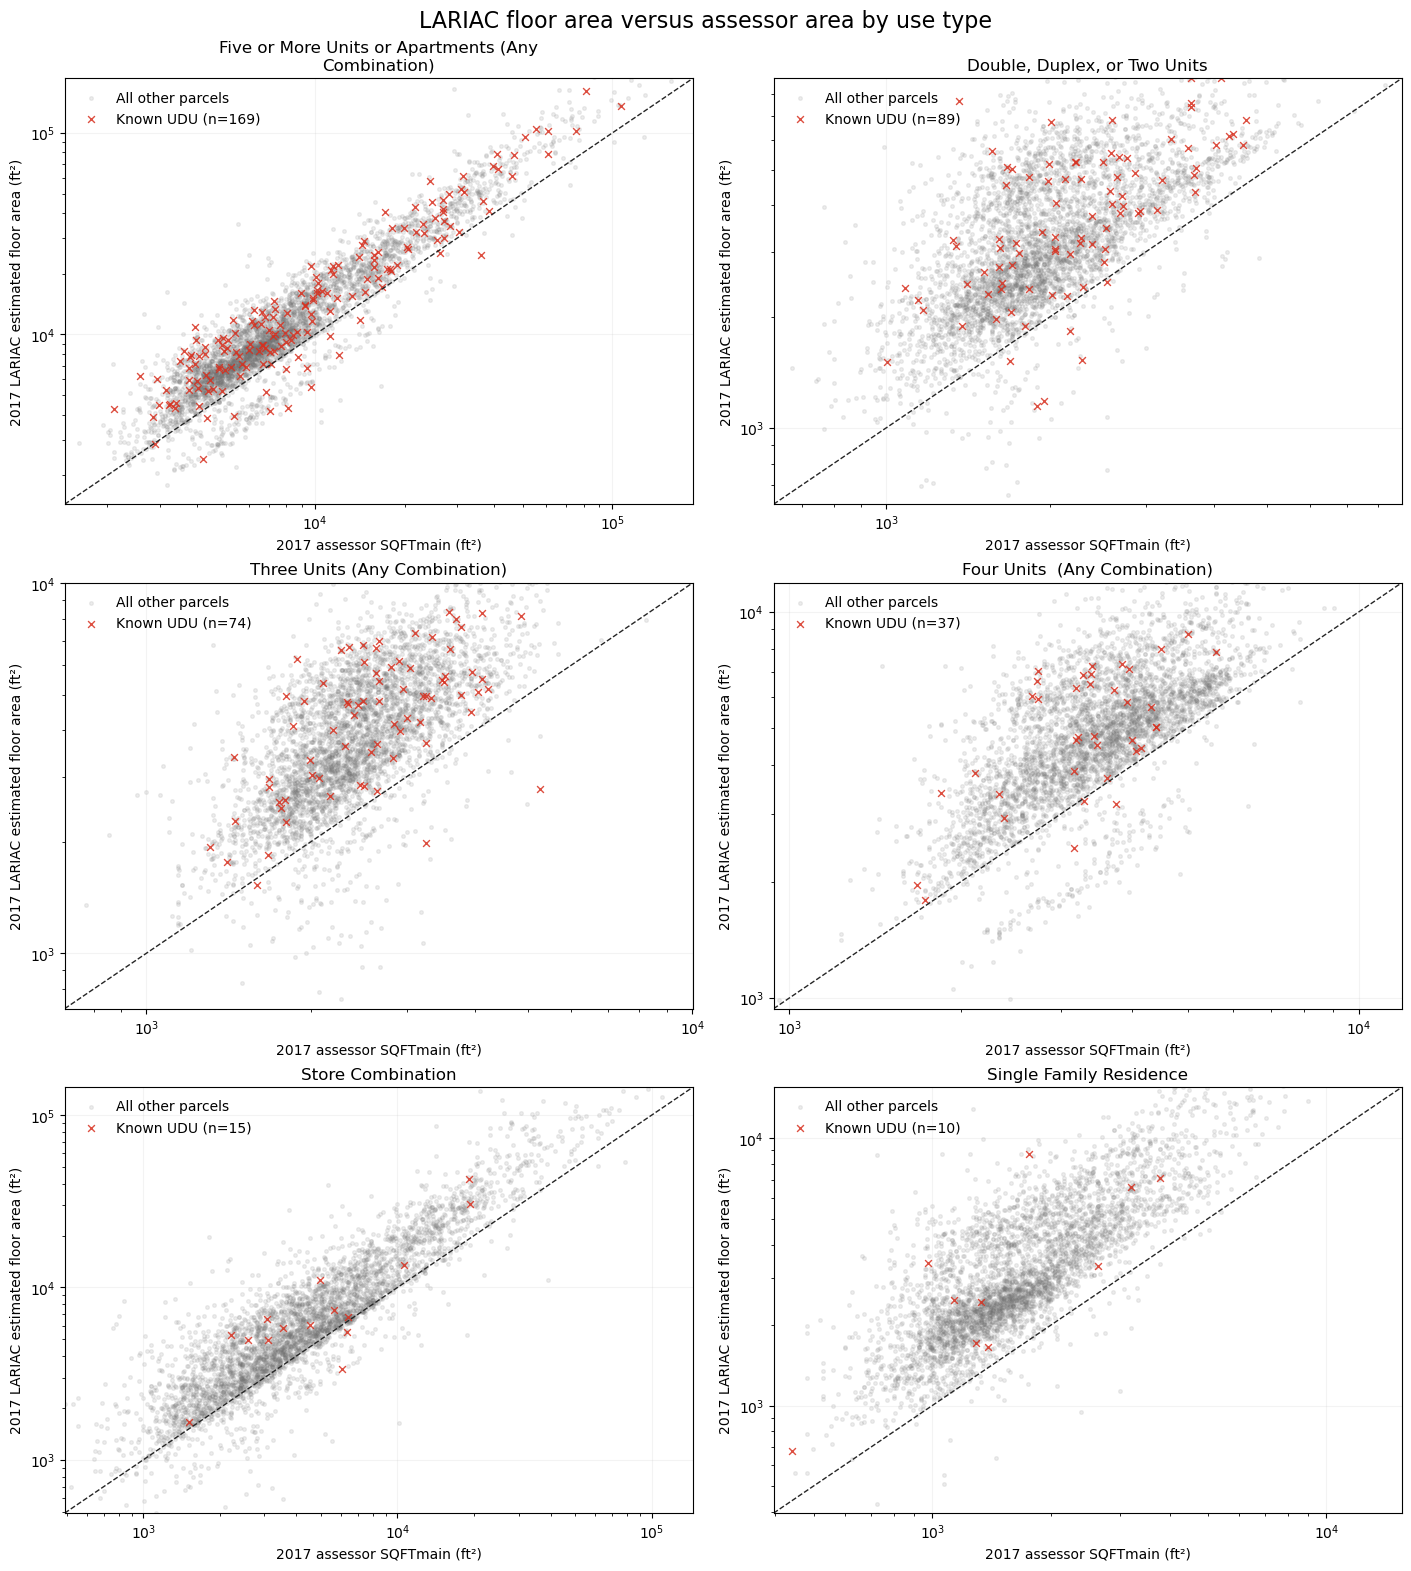

In [3]:
ncols = 2
nrows = int(np.ceil(len(modeled_use_types) / ncols))
fig, axes = plt.subplots(
    nrows, ncols, figsize=(14, 5.2 * nrows), constrained_layout=True
)
axes = np.atleast_1d(axes).ravel()
for ax, use_type in zip(axes, modeled_use_types):
    group = method1_input.loc[method1_input['SpecificUseType'].eq(use_type)]
    other = group.loc[~group['is_known_udu']]
    if len(other) > 4000:
        other = other.sample(4000, random_state=42)
    known = group.loc[group['is_known_udu']]
    ax.scatter(
        other['assessor.sqft'], other['building.floor_area'],
        s=7, alpha=0.12, color='#737373', rasterized=True,
        label='All other parcels',
    )
    ax.scatter(
        known['assessor.sqft'], known['building.floor_area'],
        s=24, alpha=0.85, color='#d7301f', marker='x', linewidth=1.0,
        label=f'Known UDU (n={len(known):,})',
    )
    values = pd.concat([
        group['assessor.sqft'], group['building.floor_area']
    ]).dropna()
    lower = max(10, float(values.quantile(0.001)))
    upper = float(values.quantile(0.995))
    ax.plot([lower, upper], [lower, upper], '--', color='#252525', linewidth=1)
    ax.set(xscale='log', yscale='log', xlim=(lower, upper), ylim=(lower, upper))
    ax.set_title('\n'.join(textwrap.wrap(use_type, 42)))
    ax.set_xlabel('2017 assessor SQFTmain (ft²)')
    ax.set_ylabel('2017 LARIAC estimated floor area (ft²)')
    ax.grid(alpha=0.15)
    ax.legend(frameon=False, loc='upper left')
for ax in axes[len(modeled_use_types):]:
    ax.remove()
fig.suptitle('LARIAC floor area versus assessor area by use type', fontsize=16)
plt.show()

In [4]:
def build_method1_features(
    data,
    percentile_cutoff=0.025,
    minimum_raw_residual=0.0,
    *,
    ain_col='AIN',
    use_type_col='SpecificUseType',
    lariac_floor_area_col='building.floor_area',
    assessor_area_col='assessor.sqft',
):
    """Build Method 1 agreement features at the single-AIN parcel level."""
    required = {
        ain_col, use_type_col, lariac_floor_area_col, assessor_area_col
    }
    missing = required.difference(data.columns)
    if missing:
        raise ValueError(f'Missing Method 1 columns: {sorted(missing)}')

    features = data[[ain_col, use_type_col]].copy()
    features['raw_residual_sqft'] = (
        data[lariac_floor_area_col] - data[assessor_area_col]
    )
    features['_absolute_residual_sqft'] = features['raw_residual_sqft'].abs()
    features['abs_residual_pct_rank_by_use_type'] = (
        features.groupby(use_type_col)['_absolute_residual_sqft']
        .rank(method='average', pct=True)
    )
    features['method1_agreement'] = (
        features['abs_residual_pct_rank_by_use_type'].le(percentile_cutoff)
        & features['raw_residual_sqft'].gt(minimum_raw_residual)
    )
    return (
        features[[
            ain_col, 'raw_residual_sqft',
            'abs_residual_pct_rank_by_use_type', 'method1_agreement',
        ]]
        .rename(columns={ain_col: 'AIN'})
        .sort_values('AIN')
        .reset_index(drop=True)
    )

method1_features = build_method1_features(method1_input)
display(pd.Series({
    'Output AINs': len(method1_features),
    'Method 1 agreement AINs': int(method1_features['method1_agreement'].sum()),
    'Agreement share': method1_features['method1_agreement'].mean(),
}).to_frame('value'))
display(method1_features.head())

,value
Output AINs,404450.000000
Method 1 agreement AINs,7846.000000
Agreement share,0.019399


,AIN,raw_residual_sqft,abs_residual_pct_rank_by_use_type,method1_agreement
0,2017030020,2532.95,0.762106,False
1,2017030021,3015.72,0.822922,False
2,2017030022,5997.52,0.962949,False
3,2017036005,5096.05,0.945227,False
4,2017036006,19469.21,0.998638,False
